In [1]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
from astropy.table import Table
import sim_analysis_utilities as utilities

import matplotlib as mpl
mpl.rcParams['savefig.dpi'] = 'figure'
mpl.rcParams['savefig.jpeg_quality'] = 98
import matplotlib.pyplot as plt

import matplotlib.lines as mlines

Populating the interactive namespace from numpy and matplotlib


In [2]:
anaDir     =   './wrkDir/s19/s19-1/anaCat_newS19Mask/'

nbin1       =   20
fwhm_bin    =   np.linspace(0.3,0.9,nbin1)
fwhm_bin_0  =   fwhm_bin[:-1]
fwhm_bin_1  =   fwhm_bin[1:]
gridPsf     =   (fwhm_bin_0+fwhm_bin_1)/2.
var_bin     =   np.linspace(0.001,0.01,nbin1)
var_bin_0   =   var_bin[:-1]
var_bin_1   =   var_bin[1:]
gridNoi     =   (var_bin_0+var_bin_1)/2.

disnames    =   ('gridNoi','histNoi','gridPsf','histPsf','num')

In [3]:
Dir='./wrkDir/s19/s19-1/.catalog_obs_reGaus_calibrated/fields/'

obsDis_var  =   np.zeros(nbin1-1)
obsDis_fwhm =   np.zeros(nbin1-1)
obsNum      =   np.zeros(nbin1-1)

simDis_var  =   np.zeros(nbin1-1)
simDis_fwhm =   np.zeros(nbin1-1)
simNum      =   np.zeros(nbin1-1)

simRDis_var  =   np.zeros(nbin1-1)
simRDis_fwhm =   np.zeros(nbin1-1)
simRNum      =   np.zeros(nbin1-1)

figN=   plt.figure()
figP=   plt.figure()

for ii,fieldname in enumerate(utilities.field_names):
    # observation
    inFname =   os.path.join(Dir,'%s_calibrated.fits' %(fieldname))
    data    =   pyfits.getdata(inFname)
    fwhms   =   utilities.get_psf_size(data)
    varNois =   utilities.get_noi_var(data)
    histNoi =   np.histogram(varNois,bins=var_bin,density=True)[0]
    histPsf =   np.histogram(fwhms,bins=fwhm_bin,density=True)[0]
    t_dis_obs=  Table(data=[gridNoi,histNoi,gridPsf,histPsf,len(data)*np.ones(len(gridNoi))],names=disnames)

    obsDis_var  +=  t_dis_obs['histNoi']*t_dis_obs['num']
    obsDis_fwhm +=  t_dis_obs['histPsf']*t_dis_obs['num']
    obsNum      +=  t_dis_obs['num']
    
    # simulations
    anaFieldDir =   os.path.join(anaDir,'%s' %(fieldname))
    simOFname   =   os.path.join(anaFieldDir,'varPSF_dis_rw.csv')
    t_dis_sim   =   Table.read(simOFname)
    
    simRDis_var +=  t_dis_sim['histNoi']*t_dis_sim['num']
    simRDis_fwhm+=  t_dis_sim['histPsf']*t_dis_sim['num']
    simRNum     +=  t_dis_sim['num']

    axN =   figN.add_subplot(3,3,ii+1)
    gg1 =   t_dis_obs['gridNoi']*100
    hh1 =   t_dis_obs['histNoi']
    gg2 =   t_dis_sim['gridNoi']*100
    hh2 =   t_dis_sim['histNoi']
    dg  =   gg1[1]-gg1[0]
    axN.plot(gg1,hh1,'-',label='obs',c='b')
    axN.plot(gg2,hh2,'--',label='sim',c='r')
    ave1=   np.sum(gg1*hh1)*dg/100.
    ave2=   np.sum(gg2*hh2)*dg/100.
    axN.axvline(x=ave1,ls='-',c='blue')
    axN.axvline(x=ave2,ls='--',c='red')
    ymin,ymax=axN.get_ylim()
    axN.text(0.8,0.78*ymax, '%.2f' %ave1,
        color='blue')
    axN.text(0.8,0.52*ymax, '%.2f' %ave2,
        color='red')
    axN.set_xlabel(r'noise variance [$\times 10^2$]')
    axN.set_title(fieldname)

    axP =   figP.add_subplot(3,3,ii+1)
    gg1 =   t_dis_obs['gridPsf']
    hh1 =   t_dis_obs['histPsf']
    gg2 =   t_dis_sim['gridPsf']
    hh2 =   t_dis_sim['histPsf']
    dg  =   gg1[1]-gg1[0]
    axP.plot(gg1,hh1,'-',label='obs',c='b')
    axP.plot(gg2,hh2,'--',label='sim',c='r')
    ave1=   np.sum(gg1*hh1)*dg
    ave2=   np.sum(gg2*hh2)*dg
    axP.axvline(x=ave1,ls='-',c='blue')
    axP.axvline(x=ave2,ls='--',c='red')

    ymin,ymax=axP.get_ylim()
    axP.text(0.8,0.78*ymax, '%.2f' %ave1,
        color='blue')
    axP.text(0.8,0.52*ymax, '%.2f' %ave2,
        color='red')
    axP.set_xlabel('PSF FWHM [arcsec]')
    axP.set_title(fieldname)

In [4]:
obsDis_var /=obsNum
obsDis_fwhm/=obsNum

simRDis_var /=simRNum
simRDis_fwhm/=simRNum

axN =   figN.add_subplot(3,3,7)
axN.plot(gridNoi*100,obsDis_var,'-',label='obs',c='b')
axN.plot(gridNoi*100,simRDis_var,'--',label='sim',c='r')
dg  =   (gridNoi[1]-gridNoi[0])*100.
ave1=   sum(gridNoi*obsDis_var)*dg
ave2=   sum(gridNoi*simRDis_var)*dg
axN.axvline(x=ave1,ls='-',c='blue')
axN.axvline(x=ave2,ls='--',c='red')
ymin,ymax=axN.get_ylim()
axN.text(0.8,0.78*ymax, '%.2f' %ave1,
    color='blue')
axN.text(0.8,0.52*ymax, '%.2f' %ave2,
    color='red')

axN.set_xlabel(r'noise variance [$\times 10^2$]')
axN.set_title('All')
axN       =   figN.add_subplot(3,3,8)
data_line = mlines.Line2D([], [], color='blue', ls='-', label='Observation')
sims_line = mlines.Line2D([], [], color='red', ls='-',label='Simulation')
axN.legend(handles=[data_line,sims_line],fontsize=15)
axN.set_axis_off()
figN.tight_layout()

axP =   figP.add_subplot(3,3,7)
axP.plot(gridPsf,obsDis_fwhm,'-',label='obs',c='b')
axP.plot(gridPsf,simRDis_fwhm,'--',label='sim',c='r')
dg  =   gridPsf[1]-gridPsf[0]
ave1=sum(gridPsf*obsDis_fwhm)*dg
ave2=sum(gridPsf*simRDis_fwhm)*dg
axP.axvline(x=ave1,ls='-',c='blue')
axP.axvline(x=ave2,ls='--',c='red')
ymin,ymax=axP.get_ylim()
axP.text(0.8,0.78*ymax, '%.2f' %ave1,
    color='blue')
axP.text(0.8,0.52*ymax, '%.2f' %ave2,
    color='red')
axP.set_xlabel('PSF FWHM [arcsec]')
axP.set_title('All')
axP       =   figP.add_subplot(3,3,8)
data_line = mlines.Line2D([], [], color='blue', ls='-', label='Observation')
sims_line = mlines.Line2D([], [], color='red', ls='-',label='Simulation')
axP.legend(handles=[data_line,sims_line],fontsize=15)
axP.set_axis_off()
figP.tight_layout()

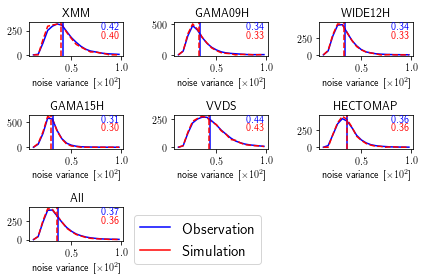

In [5]:
figN

In [6]:
pltDir  =   'wrkDir/s19/s19-1/plot/psfNoi/'
figN.savefig(os.path.join(pltDir,'noiVar_reCheck.eps'))
figP.savefig(os.path.join(pltDir,'psfFWHM_reCheck.eps'))
figN.savefig(os.path.join(pltDir,'noiVar_reCheck.png'))
figP.savefig(os.path.join(pltDir,'psfFWHM_reCheck.png'))